# Walk-forward results

These are the saved test-block metrics. This notebook is not a place to pick a new model.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd()
if not (root / 'pyproject.toml').exists():
    root = root.parent
metrics = pd.DataFrame(json.loads((root / 'reports' / 'metrics.json').read_text()))
net = metrics.loc[(metrics['book'] == 'long_short') & (metrics['cost'] == 'net')].copy()
columns = [
    'model', 'ann_return', 'ann_vol', 'sharpe', 'sortino', 'max_drawdown',
    'turnover', 'hit_rate', 'rank_ic_mean', 'alpha_annual', 'alpha_t',
]
net[columns].round(4)

,model,ann_return,ann_vol,sharpe,sortino,max_drawdown,turnover,hit_rate,rank_ic_mean,alpha_annual,alpha_t
1,momentum,-0.0155,0.1371,-0.0455,-0.0636,-0.5123,1.7544,0.4633,0.0060,-0.0391,-1.1107
5,ridge,0.1047,0.1473,0.7504,1.4108,-0.2071,0.9554,0.5424,0.0239,0.0970,3.3529
9,lgbm,0.1046,0.1143,0.9296,1.9070,-0.1232,1.2681,0.5876,0.0252,0.0846,3.6049
13,mlp,0.0982,0.1250,0.8131,1.4997,-0.1902,1.0515,0.5819,0.0154,0.0888,2.9643


LightGBM has the highest net Sharpe. The MLP is close on return and behind on rank IC.
The momentum score is the one that fails.

**cumulative_ls_net.png**

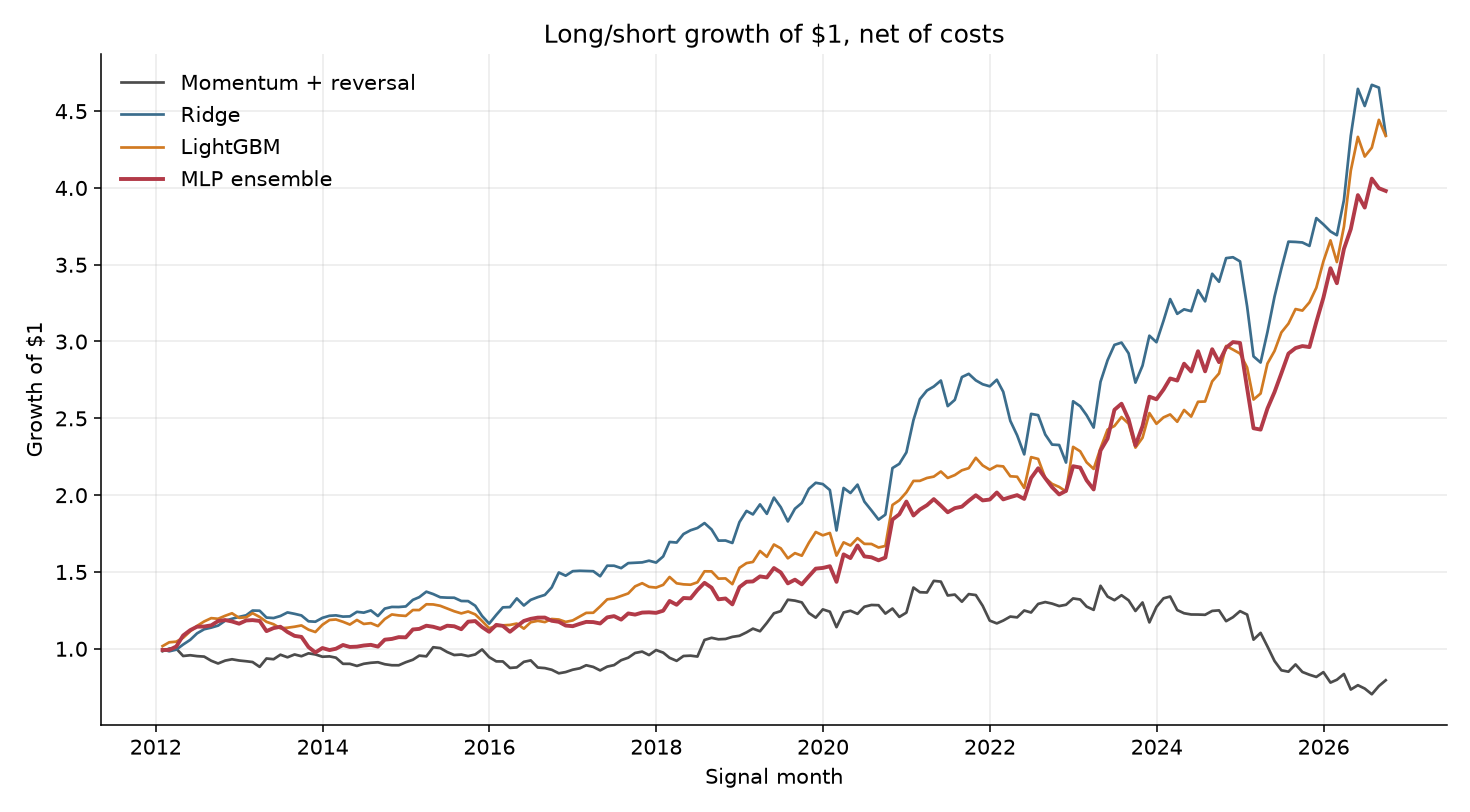

**decile_bars.png**

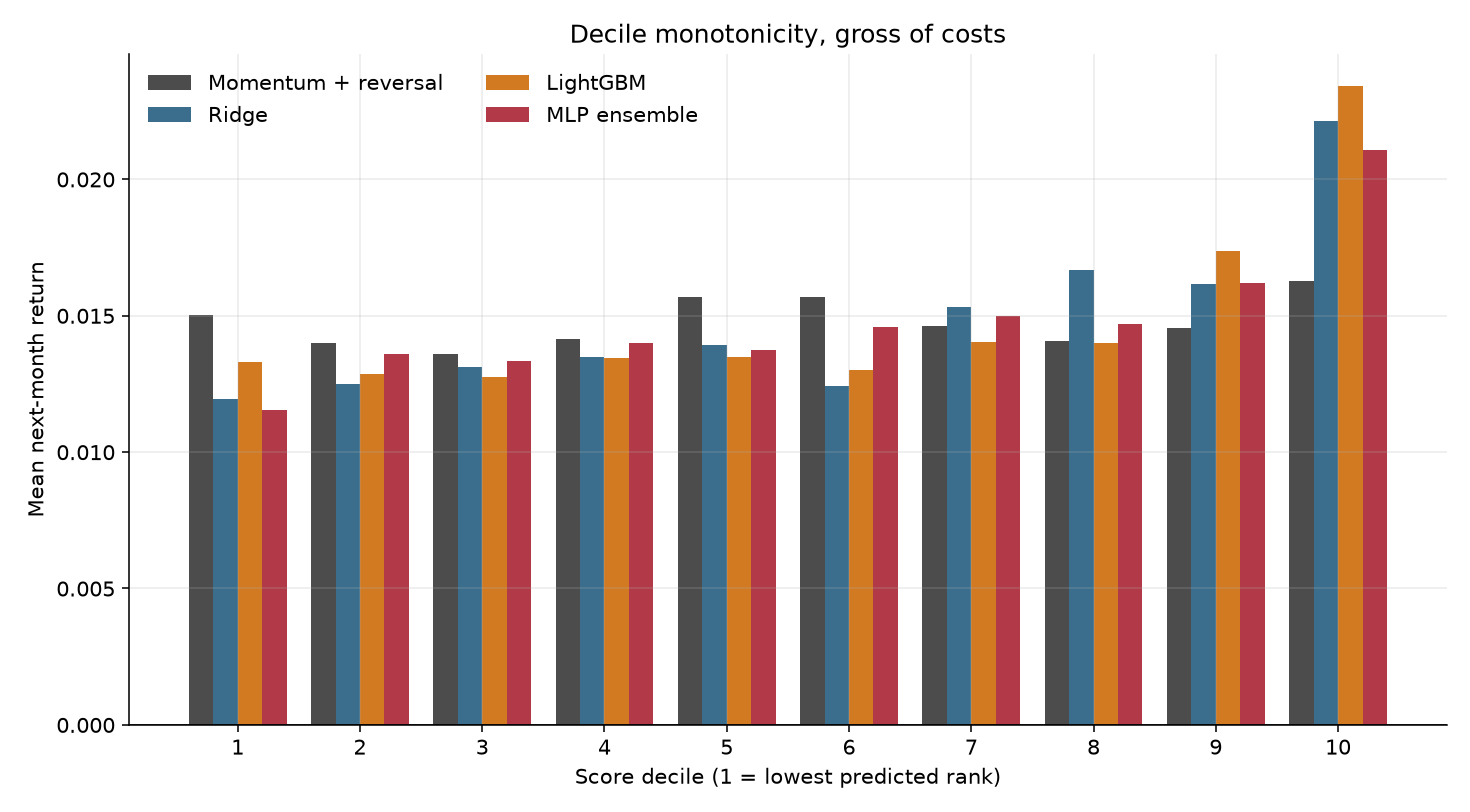

**rolling_rank_ic.png**

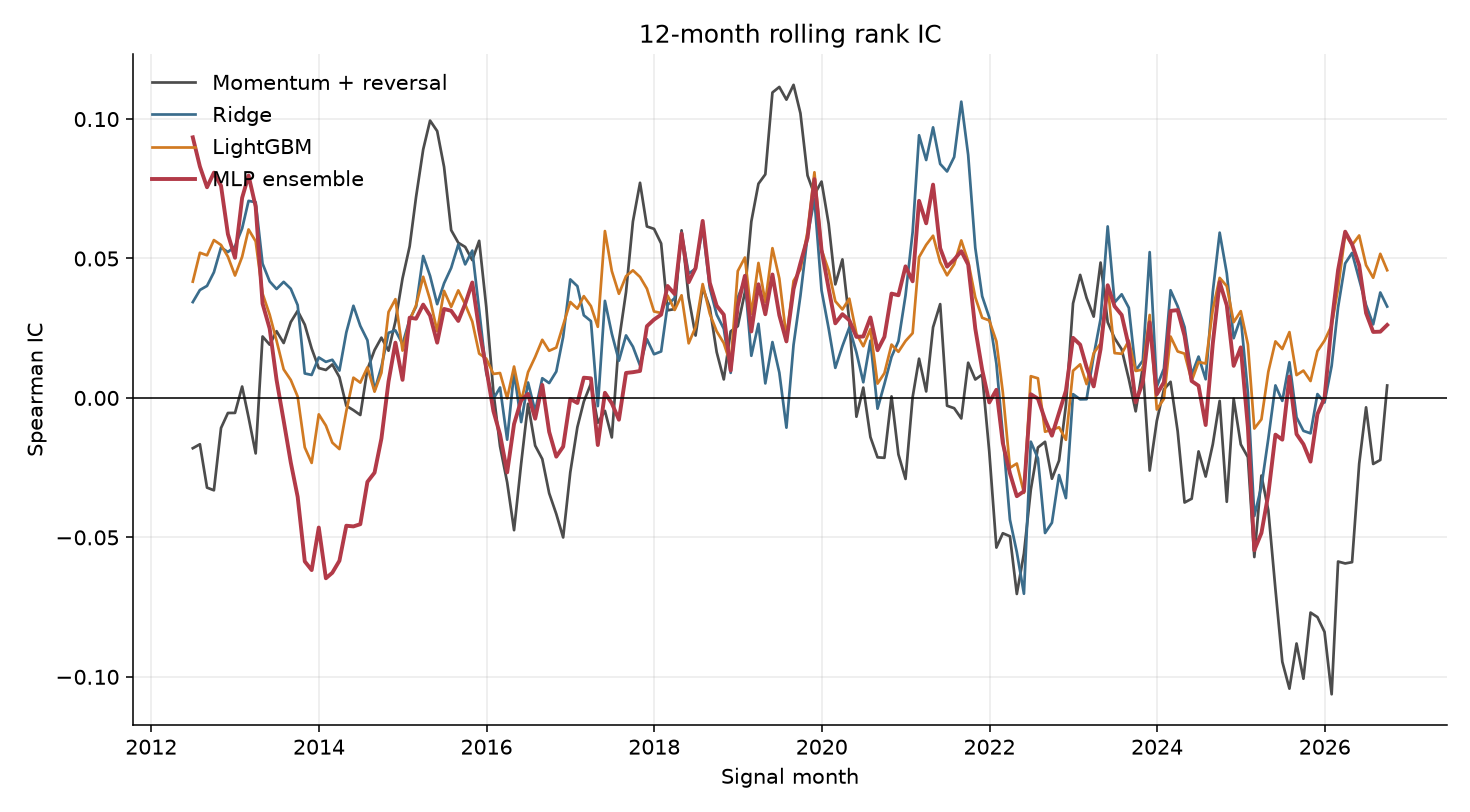

**drawdown.png**

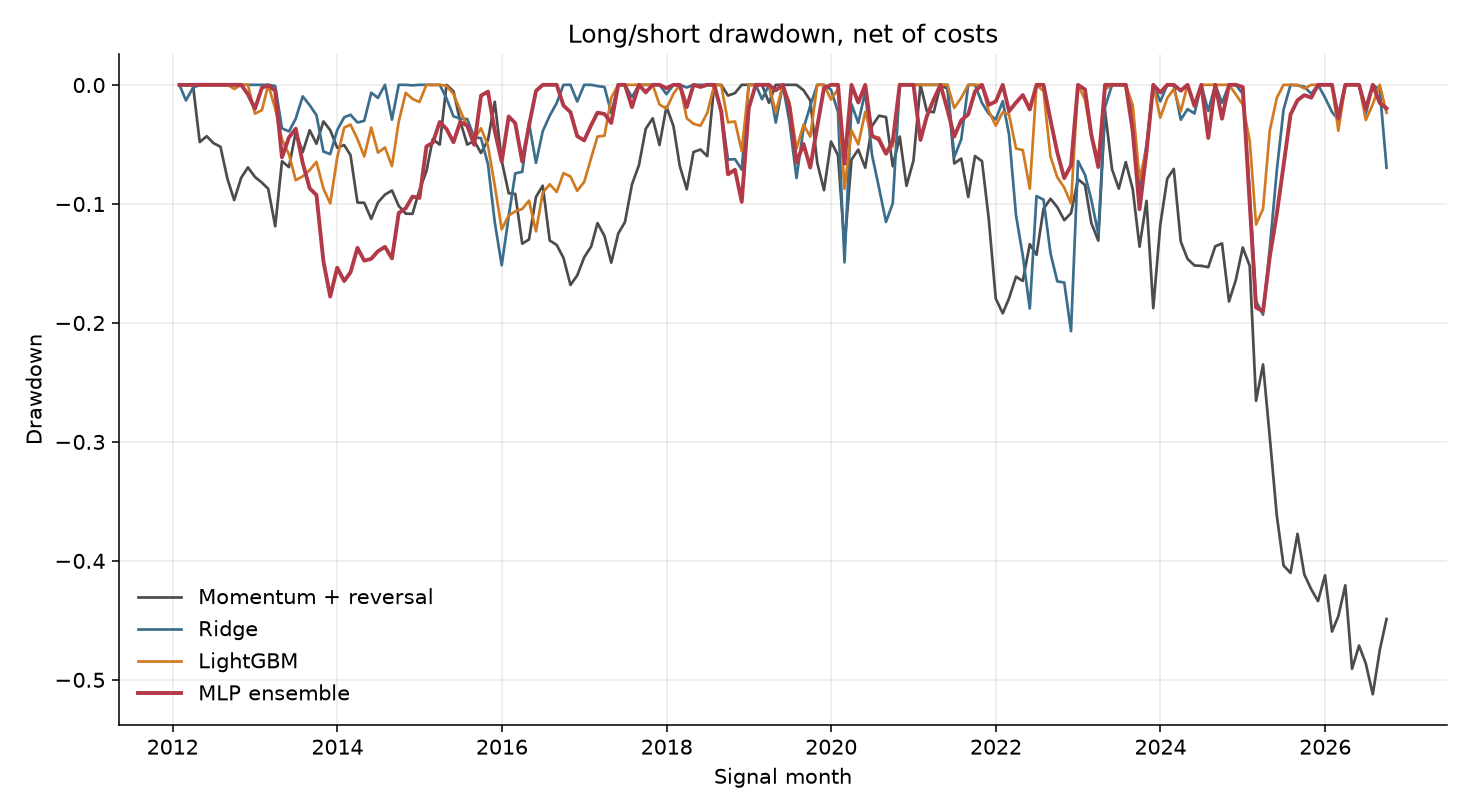

**feature_importance.png**

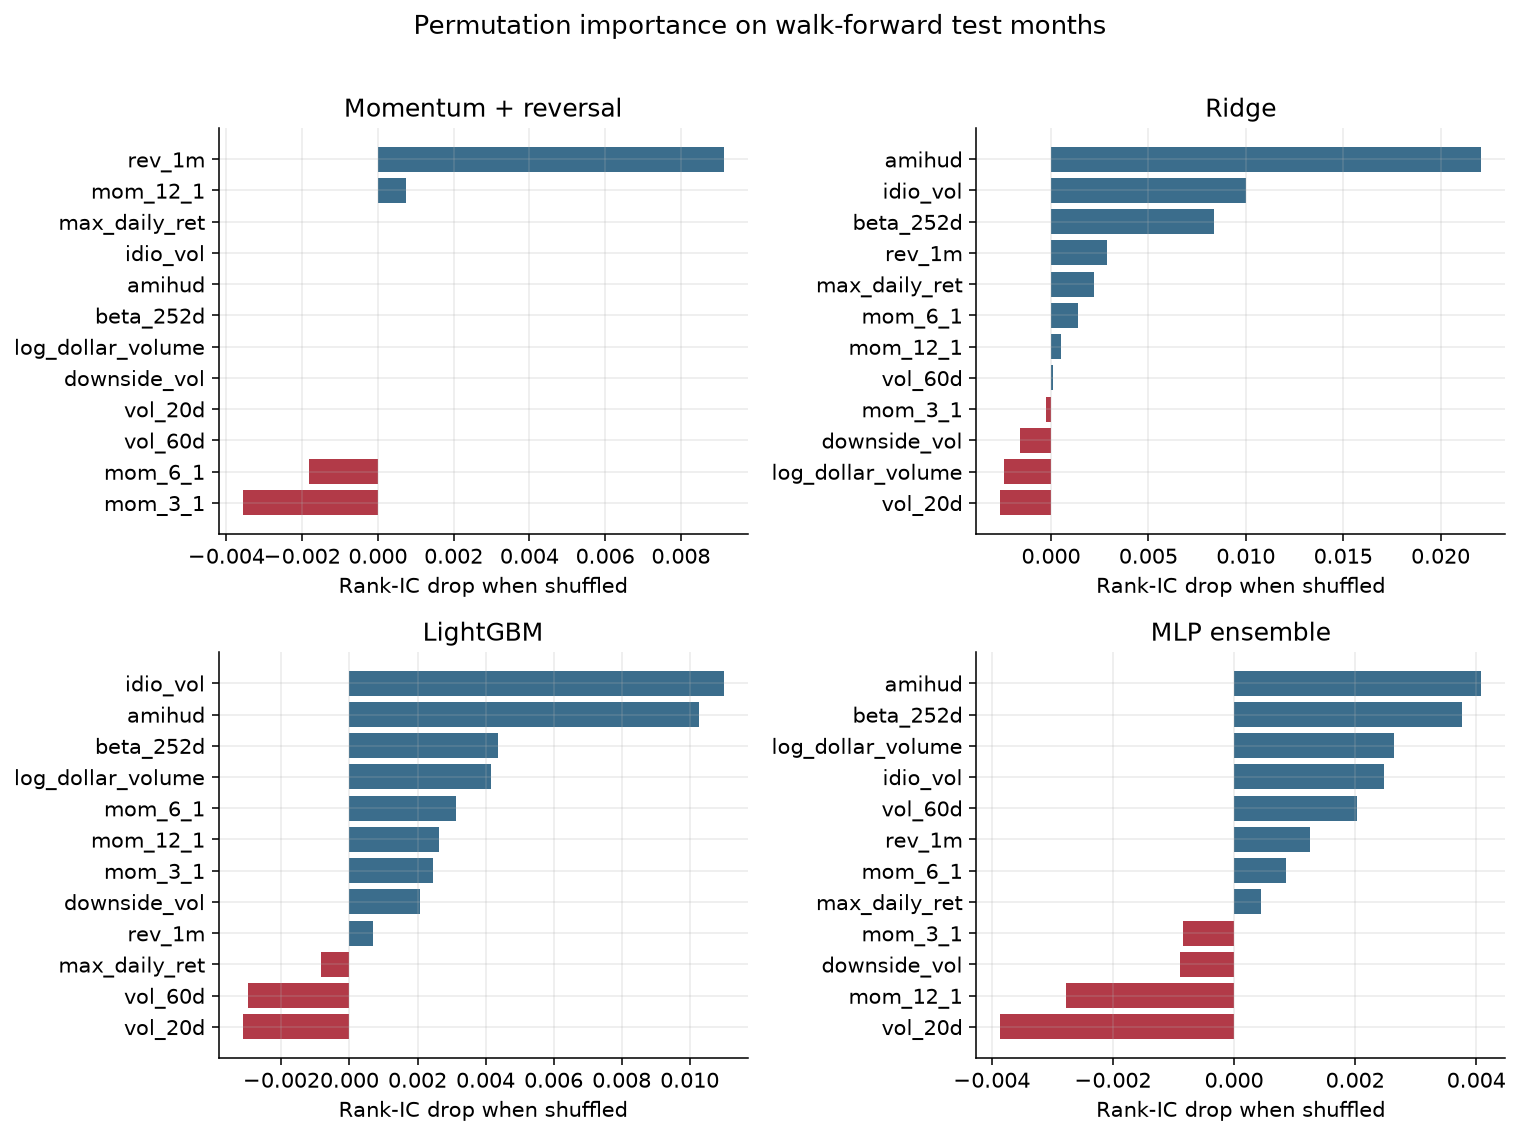

In [2]:
for name in [
    'cumulative_ls_net.png',
    'decile_bars.png',
    'rolling_rank_ic.png',
    'drawdown.png',
    'feature_importance.png',
]:
    display(Markdown(f'**{name}**'))
    display(Image(filename=str(root / 'reports' / 'figures' / name)))

In [3]:
ic = pd.read_parquet(root / 'reports' / 'ic_series.parquet')
ic.groupby('model')['rank_ic'].agg(['mean', 'std']).round(4)

,mean,std
model,,
lgbm,0.0252,0.1026
mlp,0.0154,0.1234
momentum,0.0060,0.1515
ridge,0.0239,0.1363
